# 2 · Paleo-water depth from foraminifera

**What.** Re-derive the paleo-water depths of the Coastal Range samples from the foraminifera counts in the Figshare supplementary data (Lai et al. 2022, Supp. Data 3), and average them per stratigraphic unit.

**Why.** Water depth *W* enters the backstrip directly: tectonic subsidence = water depth + loaded sediment correction. A 500 m error in *W* is a 500 m error in the answer.

**Equations.**

Planktic percentage (Eq. 1):  $\%P_s = \dfrac{P}{P + B - S}$

Hayward transfer function (Eq. 2): $W = \exp\!\left[a + \tfrac{1}{b}\ln\dfrac{\%P_s}{1-\%P_s}\right] - 0.1$

Hohenegger (2005) (Eqs. 3–4): $l_n=\sqrt{w_{min}w_{max}},\; d_n = w_{max}-w_{min},\; W=\dfrac{\sum l_n/d_n}{\sum 1/d_n}$

| symbol | meaning |
|---|---|
| P, B | counts of planktic and benthic specimens |
| S | benthic stress-marker specimens (excluded) |
| a, b | Hayward constants, a = 5.23 ± 0.042, b = 1.45 ± 0.08 |
| w_min, w_max | modern depth range of a benthic taxon (m) |
| W | paleo-water depth (m) |

> **Notation note.** The paper prints α = 1.45 (additive) and β = 5.23 (divisor). The published W values are reproduced only with the two swapped (a = 5.23 additive, b = 1.45 divisor). We use the version that reproduces the data.

Errors on *W* are first-order (delta method) over P, B, S, a and b, as in the paper.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs import data_path
from pybasinsubs.paleobathy import hayward_depth_from_counts, unit_mean
sd3 = pd.read_excel(data_path("figshare_lai2022", "SuppData3_Paleobathymetry.xlsx"), header=None)
def block(c0):
    b = sd3.iloc[13:, c0:c0 + 21].copy()
    b.columns = ["section", "id", "source", "H_comp", "H_ind", "lat", "lon", "age", "age_err", "W", "Werr",
                 "pct", "pct_err", "P", "Perr", "B", "Berr", "S", "Serr", "W_hoh", "Werr_hoh"][: b.shape[1]]
    b = b.dropna(subset=["id"])
    for c in b.columns[3:]: b[c] = pd.to_numeric(b[c], errors="coerce")
    return b
N = block(0); N.head()

,section,id,source,H_comp,H_ind,lat,lon,age,age_err,W,...,pct,pct_err,P,Perr,B,Berr,S,Serr,W_hoh,Werr_hoh
13,FF,HL133,Chang (1968),1952.388468,1952.388468,23.608669,121.510631,1.703791,0.024079,216.857104,...,0.554054,0.126390,41.0,13.0,33.0,13.0,0.0,0.0,NaN,NaN
14,FF,HL134,Chang (1968),1920.638678,1920.638678,23.609062,121.509628,1.715573,0.022928,39.442853,...,0.095238,0.107513,2.0,2.0,22.0,14.0,3.0,2.0,NaN,NaN
15,FF,HL135,Chang (1968),1608.401726,1608.401726,23.614343,121.507057,1.831444,0.015227,211.720455,...,0.545455,0.223752,12.0,8.0,10.0,6.0,0.0,0.0,NaN,NaN
16,FF,HL136,Chang (1968),1563.052399,1563.052399,23.614996,121.505799,1.848273,0.015005,122.284696,...,0.351351,0.200214,13.0,8.0,31.0,14.0,7.0,3.0,NaN,NaN
17,FF,HL137,Chang (1968),1357.586279,1357.586279,23.617256,121.504142,1.924522,0.017578,167.853841,...,0.461538,0.179287,24.0,7.0,28.0,18.0,0.0,0.0,NaN,NaN


In [3]:
W, We, f, fe = hayward_depth_from_counts(N.P.astype(float), N.Perr.astype(float), N.B.astype(float), N.Berr.astype(float),
                                        N.S.astype(float), N.Serr.astype(float))
m = (N.P.astype(float) > 0).values & np.isfinite(N.W.astype(float).values)
print(f"{m.sum()} samples with counts;  max |ΔW| vs Figshare = {np.nanmax(abs(W[m]-N.W.astype(float)[m])):.2e} m,"
      f"  max |ΔWerr| = {np.nanmax(abs(We[m]-N.Werr.astype(float)[m])):.1f} m")
# Figshare rounds the count errors (Perr, Berr, Serr) to integers; the BasinSubs CSV keeps them unrounded.
bn = pd.read_csv(data_path("coastal_range", "Thickness", "Bathymetry_N.csv")); k = bn.P > 0
W2, We2, *_ = hayward_depth_from_counts(bn.P, bn.Perr, bn.B, bn.Berr, bn.S, bn.Serr)
print(f"vs BasinSubs Bathymetry_N.csv: max |ΔW| = {np.nanmax(abs(W2[k]-bn.W[k])):.1e} m, max |ΔWerr| = {np.nanmax(abs(We2[k]-bn.Werr[k])):.1e} m")

34 samples with counts;  max |ΔW| vs Figshare = 1.63e-07 m,  max |ΔWerr| = 80.9 m
vs BasinSubs Bathymetry_N.csv: max |ΔW| = 3.4e-07 m, max |ΔWerr| = 2.6e-07 m


**Result.** W is reproduced exactly. The error of W is reproduced exactly from the BasinSubs CSV; from the Figshare table it differs by up to ~80 m only because Figshare rounds the count errors to whole specimens.

saved image/nb2_paleowater_depth_N.png


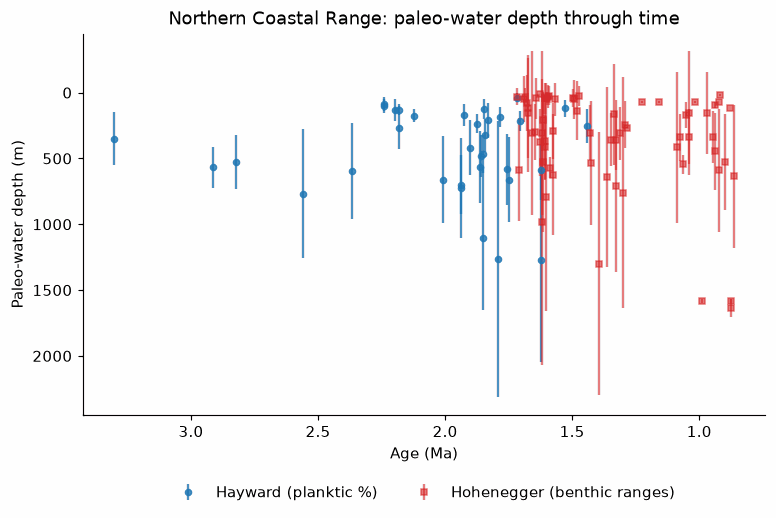

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
hoh = N[N.W_hoh.notna()] if "W_hoh" in N else N.iloc[:0]
hay = N[m]
ax.errorbar(hay.age.astype(float), hay.W.astype(float), yerr=hay.Werr.astype(float), fmt="o", ms=4, color="#1f77b4", alpha=.8, label="Hayward (planktic %)")
ax.errorbar(hoh.age.astype(float), hoh.W_hoh.astype(float), yerr=hoh.Werr_hoh.astype(float), fmt="s", ms=4, color="#d62728", alpha=.6, label="Hohenegger (benthic ranges)")
pb = pd.read_csv(data_path("coastal_range", "Thickness", "PB_Unit_N.csv"))
ages_new = pd.read_csv(data_path("coastal_range", "Thickness", "Ages_N_new.csv"))
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_xlabel("Age (Ma)"); ax.set_ylabel("Paleo-water depth (m)")
ax.set_title("Northern Coastal Range: paleo-water depth through time")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.15), ncol=2, frameon=False)
save(fig, "nb2_paleowater_depth_N.png"); plt.show()

**How to read it.** Each point is one sample; the bar is its 1σ error. Deeper is down, older is left. Blue (planktic %) and red (benthic depth ranges) are two independent methods.

- Most samples are **0–800 m deep** (upper to middle bathyal).
- The **deepest estimates (1–2 km)** cluster around 1.6–1.9 Ma and ~0.9 Ma, and they also have the largest error bars, so single deep values should not be over-interpreted.
- The planktic method covers the whole section (3.3–1.5 Ma); the benthic-range method mostly covers the younger part (1.7–0.9 Ma). Where both exist (~1.6–1.8 Ma) they overlap within error.

The per-unit water depth used in the backstrip (`PB_Unit_N.csv`) is the mean of all samples within ±0.2 Myr of each unit's age, with standard error √(Σσ²)/n:

In [5]:
pb.head(10)

,Unit,W,Werr
0,0,258.230653,258.230653
1,1,516.461306,82.115859
2,2,516.461306,82.115859
3,3,470.323983,62.284026
4,4,470.323983,62.284026
5,5,443.325345,56.698642
6,6,398.013022,86.781219
7,7,407.668181,103.076606
8,8,321.453195,60.204013
9,9,359.603597,58.424554
